# Feature check (Phase 2 · Week 4 checkpoint)

**Goal:** confirm that `app/ml/features.py` turns raw check-ins, activities and chat into a
correct daily feature table, and that the patterns planted in the synthetic users are visible
in it. Phase 3 has to find these patterns automatically.

Data comes from the demo users created by `python -m app.seed.synthetic_users`:
4 plan personas plus 30 varied people, 90 days each.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # backend/
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import select

from app.db import SessionLocal
from app.ml.features import TARGETS, build_user_features, is_leaky
from app.models import TwinProfile, User
from app.seed.synthetic_users import DEMO_DOMAIN

pd.set_option("display.width", 160, "display.max_columns", 14, "display.precision", 2)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.prop_cycle": plt.cycler(color=["#d9480f", "#1b2a41", "#8a96a8"]),
    }
)

db = SessionLocal()
users = db.scalars(
    select(User).where(User.email.like(f"%@{DEMO_DOMAIN}")).order_by(User.email)
).all()
truth = {u.email: db.get(TwinProfile, u.id).onboarding["synthetic"] for u in users}
features = {u.email: build_user_features(db, u.id) for u in users}
print(f"{len(users)} demo users loaded")

34 demo users loaded


## 1. Shape of the feature table

In [2]:
f = features[f"student@{DEMO_DOMAIN}"]
print("rows (days):", len(f), "| columns:", f.shape[1], "| imputed days:", int(f["imputed"].sum()))
base = [
    "sleep_hours",
    "mood",
    "energy",
    "stress",
    "focus",
    "min_study",
    "active_min",
    "tasks_planned",
    "completion_rate",
    "plan_ratio",
    "last_hour",
    "msg_count",
    "sentiment_mean",
]
f[base].head(8)

rows (days): 89 | columns: 110 | imputed days: 9


,sleep_hours,mood,energy,stress,focus,min_study,active_min,tasks_planned,completion_rate,plan_ratio,last_hour,msg_count,sentiment_mean
date,,,,,,,,,,,,,
2026-08-17,7.25,3.0,3.0,4.0,3.0,160.0,460.0,2.0,1.0,0.55,23.99,0.0,NaN
2026-08-18,4.25,3.0,3.0,4.0,3.0,140.0,620.0,1.0,0.0,NaN,23.99,0.0,NaN
2026-08-19,6.25,4.0,3.0,3.0,2.0,195.0,715.0,3.0,1.0,0.62,23.99,1.0,0.71
2026-08-20,6.25,4.0,3.0,3.0,2.0,195.0,715.0,3.0,1.0,0.62,23.99,1.0,0.71
2026-08-21,7.25,3.0,3.0,3.0,2.0,0.0,150.0,0.0,NaN,NaN,14.00,2.0,-0.05
2026-08-22,7.25,3.0,4.0,3.0,3.0,45.0,345.0,1.0,1.0,0.45,23.83,1.0,-0.12
2026-08-23,6.75,3.0,3.0,4.0,3.0,0.0,215.0,0.0,NaN,NaN,23.50,0.0,NaN
2026-08-24,5.75,3.0,3.0,2.0,3.0,130.0,555.0,1.0,0.0,NaN,23.99,2.0,0.02


In [3]:
# Every user: days kept, imputed days, missing values in the core check-in columns
summary = pd.DataFrame(
    [
        {
            "user": e.split("@")[0],
            "archetype": truth[e]["archetype"],
            "days": len(f),
            "imputed": int(f["imputed"].sum()),
            "cols": f.shape[1],
            "mood_missing": int(f["mood"].isna().sum()),
        }
        for e, f in features.items()
    ]
)
summary.describe().loc[["mean", "min", "max"]]

,days,imputed,cols,mood_missing
mean,89.59,5.12,109.85,0.0
min,88.00,1.00,105.00,0.0
max,90.00,9.00,110.00,0.0


## 2. Sanity checks
Lags must follow the **calendar**, not the row order. Rows are only dropped for gaps longer
than one day, and calendar flags must match the dates.

In [4]:
problems = []
for e, f in features.items():
    idx = pd.to_datetime(pd.Series(f.index))
    if not idx.is_monotonic_increasing:
        problems.append((e, "unsorted"))
    # lag1 equals the previous calendar day's value when that day exists
    prev = f["mood"].shift(1)
    consecutive = (idx.diff().dt.days == 1).values
    mism = (
        ~np.isclose(f["mood_lag1"].values[consecutive], prev.values[consecutive], equal_nan=True)
    ).sum()
    if mism:
        problems.append((e, f"lag mismatch {mism}"))
    if not (f["is_weekend"].values == (idx.dt.weekday >= 5).astype(int).values).all():
        problems.append((e, "weekend flag"))
    if not f["completion_rate"].dropna().between(0, 1).all():
        problems.append((e, "rate"))
    if (f.filter(like="min_") < 0).any().any():
        problems.append((e, "negative minutes"))
    # an imputed (filled) row must directly follow a real day
    if (f["imputed"].astype(bool).values & ~consecutive).any():
        problems.append((e, "imputed row after a gap"))
print("problems:", problems or "none")

problems: none


## 3. The plan's personas: planted patterns are visible

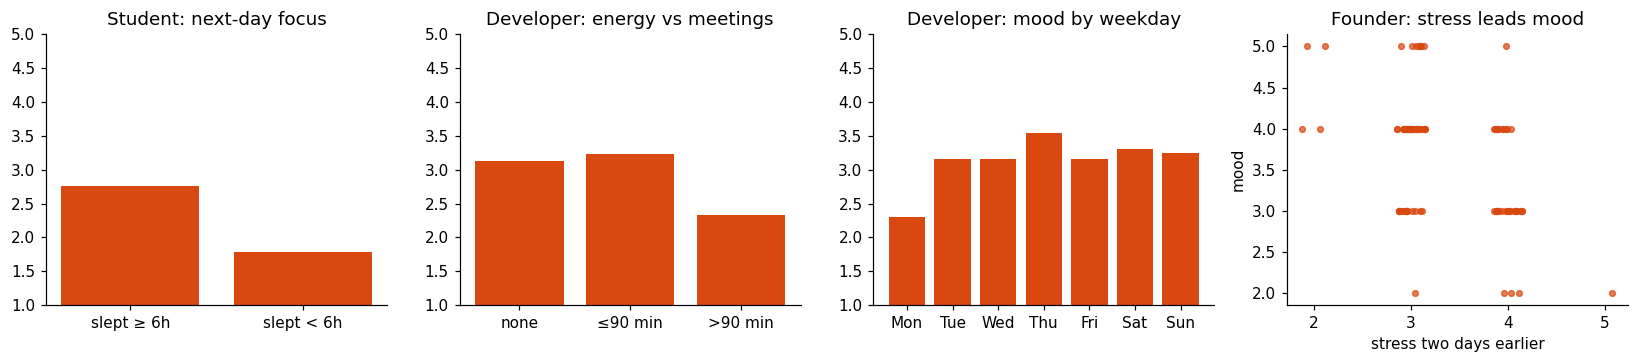

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))

s = features[f"student@{DEMO_DOMAIN}"].dropna(subset=["sleep_hours_lag1", "focus"])
g = s.groupby(s["sleep_hours_lag1"] < 6)["focus"].mean()
ax[0].bar(["slept ≥ 6h", "slept < 6h"], [g[False], g[True]])
ax[0].set_title("Student: next-day focus")
ax[0].set_ylim(1, 5)

d = features[f"developer@{DEMO_DOMAIN}"]
d = d[d["is_weekend"] == 0]
g = d.groupby(
    pd.cut(d["min_meetings"], [-1, 0, 90, 999], labels=["none", "≤90 min", ">90 min"]),
    observed=True,
)["energy"].mean()
ax[1].bar(g.index.astype(str), g.values)
ax[1].set_title("Developer: energy vs meetings")
ax[1].set_ylim(1, 5)

d = features[f"developer@{DEMO_DOMAIN}"]
g = d.groupby("weekday")["mood"].mean()
ax[2].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], g.values)
ax[2].set_title("Developer: mood by weekday")
ax[2].set_ylim(1, 5)

fo = features[f"founder@{DEMO_DOMAIN}"].dropna(subset=["stress_lag2", "mood"])
ax[3].scatter(
    fo["stress_lag2"] + np.random.uniform(-0.15, 0.15, len(fo)), fo["mood"], s=14, alpha=0.7
)
ax[3].set_xlabel("stress two days earlier")
ax[3].set_ylabel("mood")
ax[3].set_title("Founder: stress leads mood")
plt.tight_layout()
plt.show()

## 4. Planted patterns across all 34 users

For each planted pattern we compute Spearman ρ between the planted feature (at its lag) and
the target. Phase 3 will search *all* feature/target pairs blindly, with a
Benjamini-Hochberg correction; this cell only checks that the signal is there to find.

In [6]:
def rho(f, feat, target, lag):
    col = feat if lag == 0 else f"{feat}_lag{lag}"
    if col not in f or target not in f:
        return np.nan
    return f[col].corr(f[target], method="spearman")


rows = []
for e, t in truth.items():
    for p in t["patterns"]:
        r = rho(features[e], p["feature"], p["target"], p["lag"])
        sign = 1 if p["direction"] == "+" else -1
        rows.append(
            {
                "user": e.split("@")[0],
                "pattern": p["id"],
                "feature": p["feature"],
                "target": p["target"],
                "lag": p["lag"],
                "rho": r,
                "signed": r * sign,
            }
        )
planted = pd.DataFrame(rows)
print(f"{len(planted)} planted patterns in {planted['user'].nunique()} users")
print(
    f"right direction: {(planted['signed'] > 0).mean():.0%} | "
    f"|rho| >= 0.4 (plan's bar): {(planted['signed'] >= 0.4).mean():.0%} | "
    f"|rho| >= 0.3: {(planted['signed'] >= 0.3).mean():.0%}"
)
planted.groupby("pattern")["signed"].agg(["count", "mean", "min"]).sort_values("mean")

82 planted patterns in 33 users
right direction: 100% | |rho| >= 0.4 (plan's bar): 79% | |rho| >= 0.3: 94%


,count,mean,min
pattern,,,
late_next_energy,3,0.36,0.04
meetings_energy,6,0.36,0.20
exercise_next_mood,8,0.44,0.05
social_next_energy,5,0.45,0.38
exercise_energy,5,0.45,0.25
leisure_stress,4,0.46,0.34
stress_leads_mood,4,0.47,0.43
stress_next_focus,11,0.47,0.36
monday_mood,6,0.48,0.43


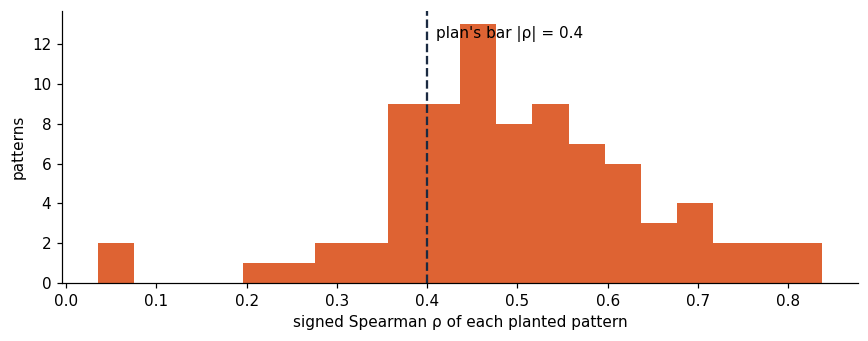

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(planted["signed"], bins=20, color="#d9480f", alpha=0.85)
ax.axvline(0.4, color="#1b2a41", ls="--")
ax.text(0.41, ax.get_ylim()[1] * 0.9, "plan's bar |ρ| = 0.4")
ax.set_xlabel("signed Spearman ρ of each planted pattern")
ax.set_ylabel("patterns")
plt.tight_layout()
plt.show()

## 5. Noise control: nothing strong should appear
The control user has no planted patterns, so any correlation here is chance. With about 200
tests, a few |ρ| near 0.3–0.4 are expected by luck alone. That is why Phase 3 applies the
Benjamini–Hochberg correction before calling anything an insight.

In [8]:
f = features[f"noise@{DEMO_DOMAIN}"]
# Skip leaky pairs (computed from the same raw values as the target, e.g. tasks_completed vs
# completion_rate) and the targets' own history: those correlations are not discoveries.
cands = [c for c in f.columns if not c.endswith(("_r3", "_r7")) and c != "imputed"]
corr = pd.Series(
    {
        (c, t): f[c].corr(f[t], method="spearman")
        for c in cands
        for t in TARGETS
        if not is_leaky(c, t) and not c.startswith(t)
    }
).dropna()
print(
    "tests:",
    len(corr),
    "| strongest |rho|:",
    round(corr.abs().max(), 3),
    "| count with |rho| >= 0.4:",
    int((corr.abs() >= 0.4).sum()),
)
corr.abs().sort_values(ascending=False).head(5)

tests: 243 | strongest |rho|: 0.399 | count with |rho| >= 0.4: 0


sentiment_mean   completion_rate    0.40
last_hour        focus              0.36
msg_count        focus              0.34
active_min_lag1  completion_rate    0.33
min_leisure      focus              0.27
dtype: float64

**Reading this notebook:** sections 1–2 show that the feature table is well formed.
Section 3 shows the plan's personas carry their patterns. Section 4 measures how strong
every planted pattern is across the 34 users. Section 5 confirms that the control user has
no strong signal. Section 4 also sets realistic expectations for Phase 3's pattern recall.

In [9]:
db.close()